In [8]:

import time
import pickle
import os
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from optimization.generators import generate_problem_data
from optimization.losses import make_quadratic_loss
from optimization.runner import run_optimization
from optimization.optimizers.collinear import CollinearGradients


# конфигурация

N_VALUES = [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
KAPPA_VALUES = [10, 30]
NUM_U0 = 1  # одно начальное приближение

NUM_ITERS = 3000
TOL_DIST = 0.05

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

RESULTS_PATH = RESULTS_DIR / "all_optimizer_configs.pkl"
CHECKPOINT_PATH = RESULTS_DIR / "all_optimizer_configs_checkpoint.pkl"

MAX_ITERS_MAP = {
    "Adam": NUM_ITERS,
    "Метод Нестерова": NUM_ITERS,
    "Метод коллинеарных градиентов": 50,
}

OPTIMIZER_NAMES = [
    "Adam",
    "Метод Нестерова",
    "Метод коллинеарных градиентов",
]


# гиперпараметры

# Adam
ADAM_LR_VALUES = [1, 0.1, 0.01]
ADAM_BETA1_VALUES = [0.8, 0.9]
ADAM_BETA2_VALUES = [0.99, 0.999]

# Метод Нестерова
NESTEROV_LR_VALUES = [ 0.01, 0.05, 0.1, 0.5]
NESTEROV_BETA_VALUES = [0.7, 0.8, 0.9]

# Метод коллинеарных градиентов
# В исходном списке 1e-9 указано дважды.
MCG_C1_VALUES = [1e-5, 1e-7, 1e-9, 1e-10, 1e-11, 1e-12]
MCG_C2_VALUES = [2.0, 4.0]


# формирование комбинаций настроек

def make_configs():

    configs = {
        "Adam": [],
        "Метод Нестерова": [],
        "Метод коллинеарных градиентов": [],
    }

    # Adam: 3 * 2 * 2 = 12 комбинаций
    idx = 1
    for lr in ADAM_LR_VALUES:
        for beta1 in ADAM_BETA1_VALUES:
            for beta2 in ADAM_BETA2_VALUES:
                configs["Adam"].append({
                    "id": f"Adam_{idx:02d}",
                    "lr": lr,
                    "betas": (beta1, beta2),
                })
                idx += 1

    # Нестеров: 4 * 3 = 12 комбинаций
    idx = 1
    for lr in NESTEROV_LR_VALUES:
        for beta in NESTEROV_BETA_VALUES:
            configs["Метод Нестерова"].append({
                "id": f"Nesterov_{idx:02d}",
                "lr": lr,
                "momentum": beta,
            })
            idx += 1

    # МКГ: 6 * 2 = 12 комбинаций
    idx = 1
    for c1 in MCG_C1_VALUES:
        for c2 in MCG_C2_VALUES:
            configs["Метод коллинеарных градиентов"].append({
                "id": f"MCG_{idx:02d}",
                "c1": c1,
                "c2": c2,
                "lr": 1.0,
                "delta0": 1e-5,
                "h0": 1e-8,
            })
            idx += 1

    return configs


OPTIMIZER_CONFIGS = make_configs()


# сиды

def seeds_for(n: int, kappa: int) -> tuple[int, int, int]:
    """Формирует seed для A, b и одного начального приближения."""
    base = 1000 * n + 100 * kappa
    return base, base + 1, base + 2


# создание оптимизатора

def make_optimizer(name, config, loss_fn):

    if name == "Adam":
        return torch.optim.Adam, {
            "lr": config["lr"],
            "betas": config["betas"],
        }

    elif name == "Метод Нестерова":
        return torch.optim.SGD, {
            "lr": config["lr"],
            "momentum": config["momentum"],
            "nesterov": True,
        }

    elif name == "Метод коллинеарных градиентов":
        return CollinearGradients, {
            "lr": config["lr"],
            "objective_fn": loss_fn,
            "c1": config["c1"],
            "c2": config["c2"],
            "delta0": config["delta0"],
            "h0": config["h0"],
        }

    raise ValueError(f"Неизвестный оптимизатор: {name}")


# сохранение результатов

def save_results(results, configs):

    save_data = {
        "results": results,
        "N_VALUES": N_VALUES,
        "KAPPA_VALUES": KAPPA_VALUES,
        "NUM_U0": NUM_U0,
        "NUM_ITERS": NUM_ITERS,
        "TOL_DIST": TOL_DIST,
        "OPTIMIZER_CONFIGS": configs,
    }

    # Сначала сохраняем во временный файл,
    # затем заменяем основной файл
    temp_path = CHECKPOINT_PATH.with_suffix(".tmp")

    with open(temp_path, "wb") as f:
        pickle.dump(save_data, f, protocol=pickle.HIGHEST_PROTOCOL)

    os.replace(temp_path, CHECKPOINT_PATH)


# эксперимент

def run_experiment():

    results = {
        kappa: {
            0: {n: {} for n in N_VALUES}
        }
        for kappa in KAPPA_VALUES
    }

    total_runs = (
        len(KAPPA_VALUES)
        * len(N_VALUES)
        * sum(len(v) for v in OPTIMIZER_CONFIGS.values())
    )

    completed_runs = 0

    for kappa in KAPPA_VALUES:

        print(f"\n==================== κ = {kappa} ====================")

        for n in N_VALUES:

            seed_A, seed_b, seed_u0 = seeds_for(n, kappa)

            # генерируем A, b и u0 один раз
            # все оптимизаторы используют одну и ту же задачу

            data = generate_problem_data(
                n=n,
                kappa=float(kappa),
                seed_A=seed_A,
                seed_b=seed_b,
                seed_u0=seed_u0,
                R=5.0,
            )

            loss_fn = make_quadratic_loss(data["A"], data["b"])

            for name in OPTIMIZER_NAMES:

                results[kappa][0][n][name] = {}

                for config in OPTIMIZER_CONFIGS[name]:

                    config_id = config["id"]

                    opt_class, opt_kwargs = make_optimizer(
                        name,
                        config,
                        loss_fn
                    )

                    u_final, hist = run_optimization(
                        opt_class,
                        u0_np=data["u0"],
                        loss_fn=loss_fn,
                        u_star_np=data["u_star"],
                        num_iters=MAX_ITERS_MAP[name],
                        tol_dist=TOL_DIST,
                        **opt_kwargs,
                    )

                    # сохраняем полный результат
                    results[kappa][0][n][name][config_id] = {
                        "config": config.copy(),
                        "u_final": u_final,
                        "history": hist.copy(),

                        "time": hist["time"],
                        "total_evals": (
                            hist["f_evals"] + hist["grad_evals"]
                        ),
                        "f_evals": hist["f_evals"],
                        "grad_evals": hist["grad_evals"],
                        "iters": hist["iters"],

                        "time_limit_reached": hist.get(
                            "time_limit_reached", False
                        ),
                    }

                    completed_runs += 1

                    # промежуточное сохранение после каждого запуска
                    save_results(results, OPTIMIZER_CONFIGS)

                    print(
                        f"κ={kappa:<3} "
                        f"n={n:<5} "
                        f"{config_id:<12} "
                        f"{name:<35} "
                        f"time={hist['time']:.3f}s "
                        f"evals={hist['f_evals'] + hist['grad_evals']} "
                        f"[{completed_runs}/{total_runs}]"
                    )

    return results


# запуск

total_runs = (
    len(KAPPA_VALUES)
    * len(N_VALUES)
    * sum(len(v) for v in OPTIMIZER_CONFIGS.values())
)

t0 = time.perf_counter()

results = run_experiment()

total_time = time.perf_counter() - t0

# итоговое сохранение
save_data = {
    "results": results,
    "N_VALUES": N_VALUES,
    "KAPPA_VALUES": KAPPA_VALUES,
    "NUM_U0": NUM_U0,
    "NUM_ITERS": NUM_ITERS,
    "TOL_DIST": TOL_DIST,
    "OPTIMIZER_CONFIGS": OPTIMIZER_CONFIGS,
    "total_time": total_time,
}

with open(RESULTS_PATH, "wb") as f:
    pickle.dump(save_data, f, protocol=pickle.HIGHEST_PROTOCOL)

print("\n==================== ГОТОВО ====================")
print(f"Всего запусков: {total_runs}")
print(f"Общее время: {total_time:.1f} с")
print(f"Результаты сохранены: {RESULTS_PATH.resolve()}")



==================== κ = 10 ====================
κ=10  n=1000  Adam_01      Adam                                time=0.031s evals=96 [1/720]
κ=10  n=1000  Adam_02      Adam                                time=0.022s evals=82 [2/720]
κ=10  n=1000  Adam_03      Adam                                time=0.044s evals=172 [3/720]
κ=10  n=1000  Adam_04      Adam                                time=0.047s evals=170 [4/720]
κ=10  n=1000  Adam_05      Adam                                time=0.014s evals=52 [5/720]
κ=10  n=1000  Adam_06      Adam                                time=0.012s evals=50 [6/720]
κ=10  n=1000  Adam_07      Adam                                time=0.030s evals=106 [7/720]
κ=10  n=1000  Adam_08      Adam                                time=0.025s evals=102 [8/720]
κ=10  n=1000  Adam_09      Adam                                time=0.040s evals=148 [9/720]
κ=10  n=1000  Adam_10      Adam                                time=0.041s evals=156 [10/720]
κ=10  n=1000  Adam_11  

In [10]:

import pickle
from pathlib import Path


# настройки

RESULTS_PATH = Path("results/all_optimizer_configs.pkl")
RANKINGS_PATH = Path("results/optimizer_config_rankings.pkl")

TOP_N = 12  # сколько лучших конфигураций выводить для каждого метода


# загрузка результатов

with open(RESULTS_PATH, "rb") as f:
    saved_data = pickle.load(f)

results = saved_data["results"]
N_VALUES = saved_data["N_VALUES"]
KAPPA_VALUES = saved_data["KAPPA_VALUES"]
OPTIMIZER_CONFIGS = saved_data["OPTIMIZER_CONFIGS"]

TOTAL_TASKS = len(KAPPA_VALUES) * len(N_VALUES)


# подсчёт суммарного времени

rankings = {}

for name, configs in OPTIMIZER_CONFIGS.items():

    rankings[name] = []

    for config in configs:

        config_id = config["id"]

        total_time = 0.0
        completed_tasks = 0
        missing_tasks = 0

        for kappa in KAPPA_VALUES:
            for n in N_VALUES:

                record = (
                    results[kappa][0][n]
                    .get(name, {})
                    .get(config_id)
                )

                if record is None:
                    missing_tasks += 1
                    continue

                total_time += record["time"]
                completed_tasks += 1

        rankings[name].append({
            "id": config_id,
            "config": config,
            "total_time": total_time,
            "completed_tasks": completed_tasks,
            "missing_tasks": missing_tasks,
        })

    # сортировка по суммарному времени
    rankings[name].sort(key=lambda x: x["total_time"])


# вывод рейтинга

print("\n==================== РЕЙТИНГ КОНФИГУРАЦИЙ ====================")

for name, ranking in rankings.items():

    print(f"\n{'=' * 90}")
    print(name)
    print("=" * 90)

    print(
        f"{'Место':<7}"
        f"{'ID':<15}"
        f"{'Суммарное время, с':<22}"
        f"{'Задач':<12}"
        f"{'Пропущено':<12}"
        f"Настройки"
    )

    for place, item in enumerate(ranking[:TOP_N], start=1):

        print(
            f"{place:<7}"
            f"{item['id']:<15}"
            f"{item['total_time']:<22.3f}"
            f"{item['completed_tasks']:<12}"
            f"{item['missing_tasks']:<12}"
            f"{item['config']}"
        )


# сохранение рейтингов

with open(RANKINGS_PATH, "wb") as f:
    pickle.dump(rankings, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"\nРейтинги сохранены: {RANKINGS_PATH.resolve()}")



==================== РЕЙТИНГ КОНФИГУРАЦИЙ ====================

Adam
Место  ID             Суммарное время, с    Задач       Пропущено   Настройки
1      Adam_06        12.080                20          0           {'id': 'Adam_06', 'lr': 0.1, 'betas': (0.8, 0.999)}
2      Adam_05        12.232                20          0           {'id': 'Adam_05', 'lr': 0.1, 'betas': (0.8, 0.99)}
3      Adam_09        14.242                20          0           {'id': 'Adam_09', 'lr': 0.01, 'betas': (0.8, 0.99)}
4      Adam_10        14.579                20          0           {'id': 'Adam_10', 'lr': 0.01, 'betas': (0.8, 0.999)}
5      Adam_12        22.376                20          0           {'id': 'Adam_12', 'lr': 0.01, 'betas': (0.9, 0.999)}
6      Adam_11        22.416                20          0           {'id': 'Adam_11', 'lr': 0.01, 'betas': (0.9, 0.99)}
7      Adam_08        24.139                20          0           {'id': 'Adam_08', 'lr': 0.1, 'betas': (0.9, 0.999)}
8      Adam

In [11]:

# вычисление среднего суммарного времени

print("\n==================== СРЕДНЕЕ ВРЕМЯ НА ВСЕ ЗАДАЧИ ====================")

for name, ranking in rankings.items():

    # учитываем только конфигурации с полным набором результатов
    config_total_times = [
        item["total_time"]
        for item in ranking
        if item["completed_tasks"] == TOTAL_TASKS
    ]

    if config_total_times:

        average_total_time = sum(config_total_times) / len(config_total_times)

        print(f"\n{name}")
        print(f"  Количество конфигураций: {len(config_total_times)}")
        print(f"  Среднее суммарное время: {average_total_time:.3f} с")
        print(f"  Минимальное суммарное время: {min(config_total_times):.3f} с")
        print(f"  Максимальное суммарное время: {max(config_total_times):.3f} с")

    else:
        print(f"\n{name}: нет конфигураций с полным набором результатов")



==================== СРЕДНЕЕ ВРЕМЯ НА ВСЕ ЗАДАЧИ ====================

Adam
  Количество конфигураций: 12
  Среднее суммарное время: 219.727 с
  Минимальное суммарное время: 12.080 с
  Максимальное суммарное время: 1219.750 с

Метод Нестерова
  Количество конфигураций: 12
  Среднее суммарное время: 617.929 с
  Минимальное суммарное время: 9.403 с
  Максимальное суммарное время: 1224.641 с

Метод коллинеарных градиентов
  Количество конфигураций: 12
  Среднее суммарное время: 15.668 с
  Минимальное суммарное время: 11.174 с
  Максимальное суммарное время: 23.184 с



==================== TOP-1 КОНФИГУРАЦИИ ====================

Adam
  ID: Adam_06
  Суммарное время: 12.080 с
  Настройки: {'id': 'Adam_06', 'lr': 0.1, 'betas': (0.8, 0.999)}

Метод Нестерова
  ID: Nesterov_02
  Суммарное время: 9.403 с
  Настройки: {'id': 'Nesterov_02', 'lr': 0.01, 'momentum': 0.8}

Метод коллинеарных градиентов
  ID: MCG_06
  Суммарное время: 11.174 с
  Настройки: {'id': 'MCG_06', 'c1': 1e-09, 'c2': 4.0, 'lr': 1.0, 'delta0': 1e-05, 'h0': 1e-08}


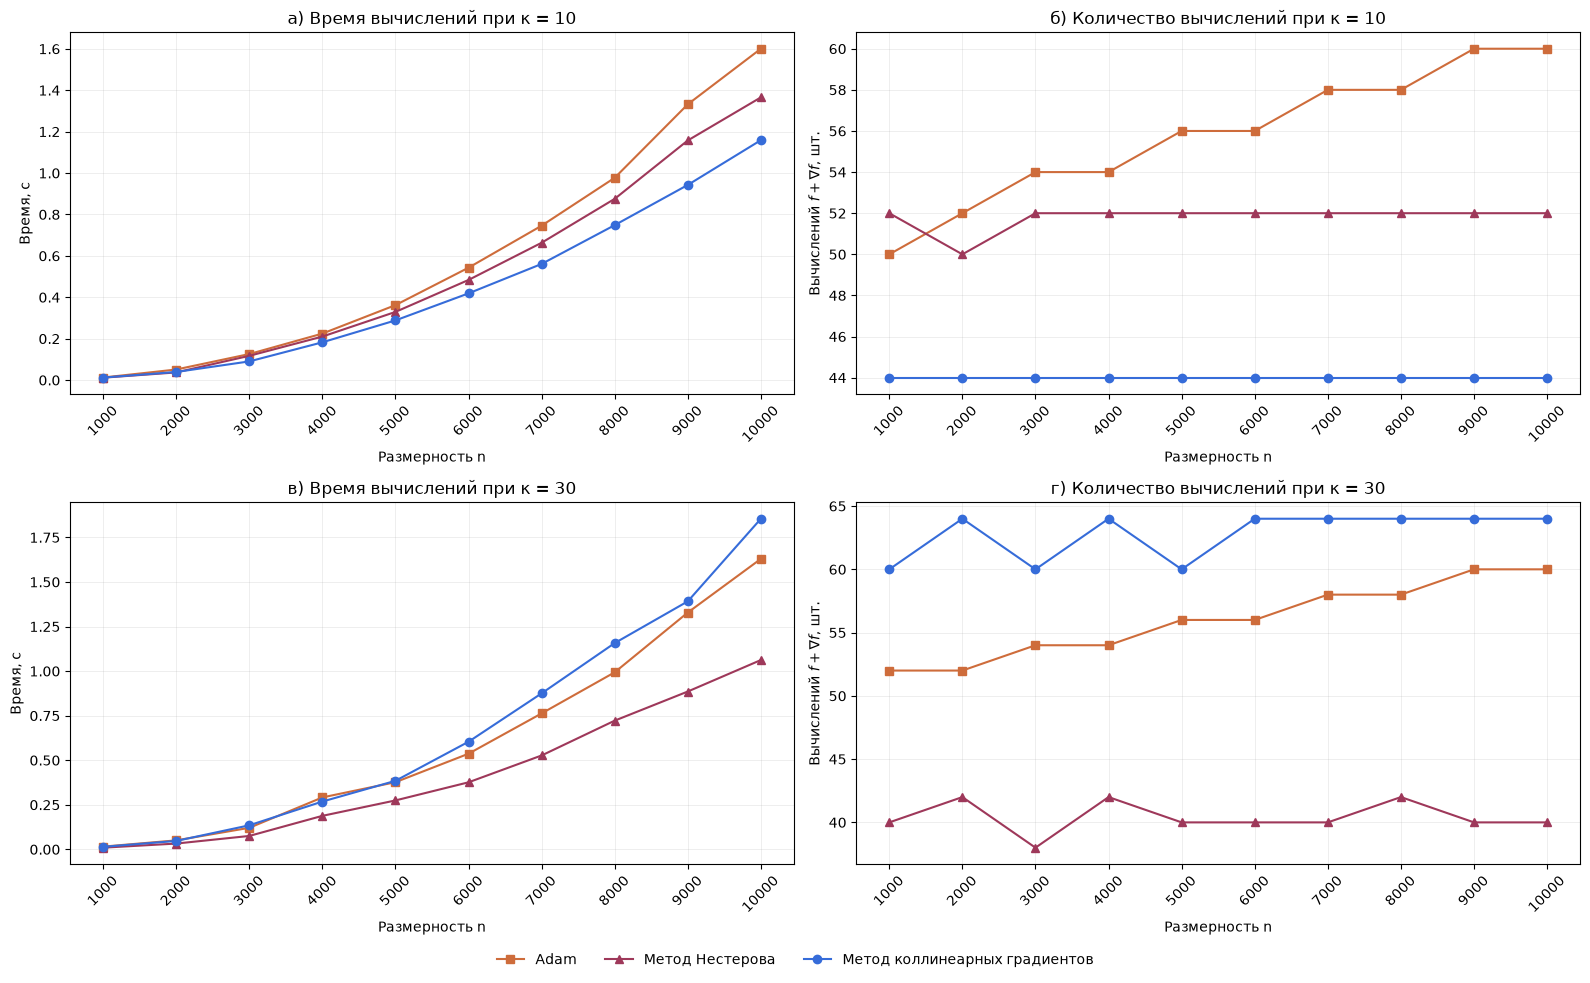


Графики сохранены: C:\Users\Mikhail\repos\Optimization\experiments\results\comparison_top1_kappa10_30.png


In [12]:
import matplotlib.pyplot as plt
from pathlib import Path
# выбор Top-1 конфигураций

OPTIMIZER_NAMES = [
    "Adam",
    "Метод Нестерова",
    "Метод коллинеарных градиентов",
]

BEST_CONFIGS = {}

print("\n==================== TOP-1 КОНФИГУРАЦИИ ====================")

for name in OPTIMIZER_NAMES:

    # берём первую конфигурацию с полным набором результатов
    best_config = next(
        (
            item for item in rankings[name]
            if item["completed_tasks"] == TOTAL_TASKS
        ),
        None
    )

    if best_config is None:
        raise ValueError(
            f"Для метода {name} нет конфигураций "
            "с полным набором результатов."
        )

    BEST_CONFIGS[name] = best_config["id"]

    print(f"\n{name}")
    print(f"  ID: {best_config['id']}")
    print(f"  Суммарное время: {best_config['total_time']:.3f} с")
    print(f"  Настройки: {best_config['config']}")


# графики

COLORS = {
    "Adam": "C1",
    "Метод Нестерова": "C2",
    "Метод коллинеарных градиентов": "C0",
}

MARKERS = {
    "Adam": "s",
    "Метод Нестерова": "^",
    "Метод коллинеарных градиентов": "o",
}

# Обозначения графиков
PLOT_LABELS = ["а)", "б)", "в)", "г)"]

# Обусловленности для построения графиков
PLOT_KAPPA_VALUES = [10, 30]

# Размерности для построения графиков
PLOT_N_VALUES = [
    1000, 2000, 3000, 4000, 5000,
    6000, 7000, 8000, 9000, 10000
]

# Проверка наличия результатов для построения графиков

for kappa in PLOT_KAPPA_VALUES:
    for n in PLOT_N_VALUES:
        for name in OPTIMIZER_NAMES:

            config_id = BEST_CONFIGS[name]

            record = (
                results.get(kappa, {})
                .get(0, {})
                .get(n, {})
                .get(name, {})
                .get(config_id)
            )

            if record is None:
                raise ValueError(
                    f"Нет данных для графика: "
                    f"{name}, {config_id}, κ={kappa}, n={n}"
                )


# построение графиков

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    facecolor="white"
)

# Общая легенда
legend_handles = []

for name in OPTIMIZER_NAMES:

    line, = axes[0, 0].plot(
        [],
        [],
        marker=MARKERS[name],
        color=COLORS[name],
        label=name
    )

    legend_handles.append(line)


for row_idx, kappa in enumerate(PLOT_KAPPA_VALUES):

    ax_time = axes[row_idx, 0]
    ax_evals = axes[row_idx, 1]

    for name in OPTIMIZER_NAMES:

        config_id = BEST_CONFIGS[name]

        times = [
            results[kappa][0][n][name][config_id]["time"]
            for n in PLOT_N_VALUES
        ]

        evals = [
            results[kappa][0][n][name][config_id]["total_evals"]
            for n in PLOT_N_VALUES
        ]

        ax_time.plot(
            PLOT_N_VALUES,
            times,
            marker=MARKERS[name],
            color=COLORS[name]
        )

        ax_evals.plot(
            PLOT_N_VALUES,
            evals,
            marker=MARKERS[name],
            color=COLORS[name]
        )

    for ax in (ax_time, ax_evals):

        ax.set_facecolor("white")
        ax.tick_params(colors="black")
        ax.xaxis.label.set_color("black")
        ax.yaxis.label.set_color("black")
        ax.title.set_color("black")

        ax.ticklabel_format(
            style="plain",
            axis="both",
            useOffset=False
        )

        for spine in ax.spines.values():
            spine.set_color("black")

    # Левый столбец: время
    plot_idx = row_idx * 2

    ax_time.set_xlabel("Размерность n")
    ax_time.set_ylabel("Время, с")

    ax_time.set_title(
        f"{PLOT_LABELS[plot_idx]} Время вычислений при κ = {kappa}"
    )

    ax_time.set_xticks(PLOT_N_VALUES)
    ax_time.tick_params(axis="x", rotation=45)
    ax_time.grid(True, alpha=0.3)

    # Правый столбец: количество вычислений

    ax_evals.set_xlabel("Размерность n")
    ax_evals.set_ylabel(r"Вычислений $f + \nabla f$, шт.")

    ax_evals.set_title(
        f"{PLOT_LABELS[plot_idx + 1]} Количество вычислений при κ = {kappa}"
    )

    ax_evals.set_xticks(PLOT_N_VALUES)
    ax_evals.tick_params(axis="x", rotation=45)
    ax_evals.grid(True, alpha=0.3)


# Одна общая легенда внизу

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=3,
    fontsize=10,
    frameon=False,
    labelcolor="black"
)

# Настройка расположения

fig.tight_layout(rect=(0, 0.045, 1, 1))

# Сохранение графиков

out_path = Path("results/comparison_top1_kappa10_30.png")

fig.savefig(
    out_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

print(f"\nГрафики сохранены: {out_path.resolve()}")
